# Vision-Language Models in 3 parts

1. **CLIP**: search images with a text prompt, and search images with another image
2. **LLaVA 1.5**: ask a question about your own picture
3. **Qwen3-VL-8B-Instruct**: ask the *same* question about the *same* picture and compare

**Colab:** `Runtime → Change runtime type → T4 GPU`, then run the cells from top to bottom.
**Laptop:** needs an NVIDIA GPU. 8 GB of VRAM is enough but tight for Part 3, so close other programs that use the GPU.

The two big models (7B and 8B parameters) would not fit in 12-15 GB of GPU memory at full precision,
so we load them in **4-bit** (`bitsandbytes`). This cuts memory to ~5-6 GB per model with a small quality loss.

> The first run downloads ~15 GB per big model from Hugging Face, so be patient.

In [1]:
%pip install -q -U transformers accelerate bitsandbytes sentence-transformers datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import torch
import matplotlib.pyplot as plt
from PIL import Image

assert torch.cuda.is_available(), "No GPU found. On Colab: Runtime -> Change runtime type -> T4 GPU"
print("GPU:", torch.cuda.get_device_name(0))

# RTX 4070 supports bfloat16, the Colab T4 only supports float16
dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
print("Using dtype:", dtype)

GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Using dtype: torch.bfloat16


---
# Part 1: CLIP image retrieval

CLIP has two encoders, one for images and one for text. Both turn their input into a vector in the **same space**,
so a sentence and a matching picture end up close to each other. Retrieval is then just:

1. encode every image once,
2. encode the query (text **or** image),
3. return the images with the highest cosine similarity.

In [3]:
from sentence_transformers import SentenceTransformer

clip = SentenceTransformer("clip-ViT-B-32")   # small and fast CLIP (OpenAI weights)

c:\Users\matin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 1372.12it/s]


We need a collection of images to search in. We take the first 800 real photos from **COCO**
(everyday scenes: animals, food, street scenes, sports, kitchens, trains...).
We use *streaming*, so only the photos we need are downloaded, not the whole dataset (this takes seconds, not minutes).
If COCO is unavailable, the cell falls back to Flickr8k. Increase `N` for a bigger collection.

In [4]:
from datasets import load_dataset

N = 800   # number of photos in our collection


def load_photos(name, split, n):
    stream = load_dataset(name, split=split, streaming=True)   
    photos = []
    for row in stream.take(n):
        img = row["image"].convert("RGB")
        img.thumbnail((512, 512))                           
        photos.append(img)
    return photos


try:
    images = load_photos("detection-datasets/coco", "val", N)
except Exception as e:
    print("COCO failed, using Flickr8k instead:", e)
    images = load_photos("jxie/flickr8k", "test", N)

print(len(images), "images")

800 images


In [5]:
# Encode all images once. normalize_embeddings=True makes "dot product" = "cosine similarity".
image_embeddings = clip.encode(images, batch_size=128, convert_to_tensor=True,
                               normalize_embeddings=True, show_progress_bar=True)
print(image_embeddings.shape)   # (number of images, 512)

Batches: 100%|██████████| 7/7 [00:03<00:00,  2.08it/s]

torch.Size([800, 512])


In [6]:
def show(imgs, labels, title):
    fig, axes = plt.subplots(1, len(imgs), figsize=(3.2 * len(imgs), 3.4))
    for ax, img, label in zip(axes, imgs, labels):
        ax.imshow(img)
        ax.set_title(label, fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


def search_by_text(prompt, k=5):
    query = clip.encode(prompt, convert_to_tensor=True, normalize_embeddings=True)
    scores = image_embeddings @ query                 # similarity with every image
    top = scores.topk(k)
    show([images[i] for i in top.indices.tolist()],
         [f"{s:.2f}" for s in top.values.tolist()],
         f'Text prompt: "{prompt}"')


def search_by_image(query_image, k=3):
    query = clip.encode(query_image, convert_to_tensor=True, normalize_embeddings=True)
    scores = image_embeddings @ query
    top = scores.topk(k)
    show([query_image] + [images[i] for i in top.indices.tolist()],
         ["QUERY"] + [f"{s:.2f}" for s in top.values.tolist()],
         "Image query")

### 1a. Text → images

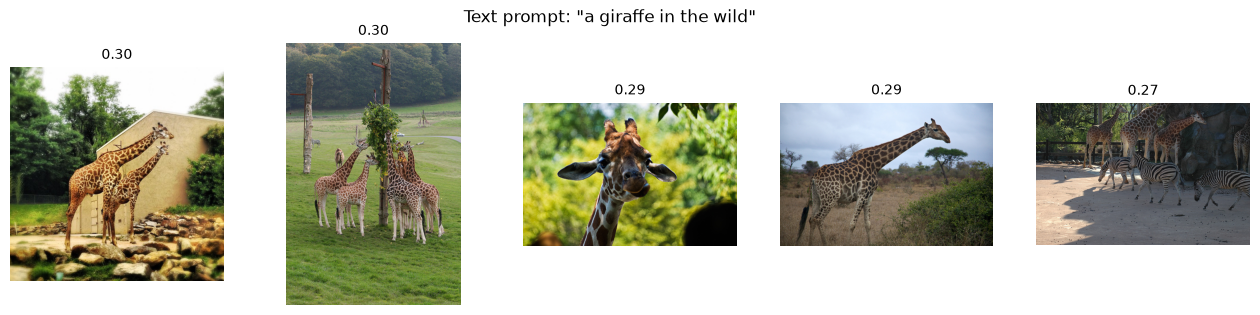

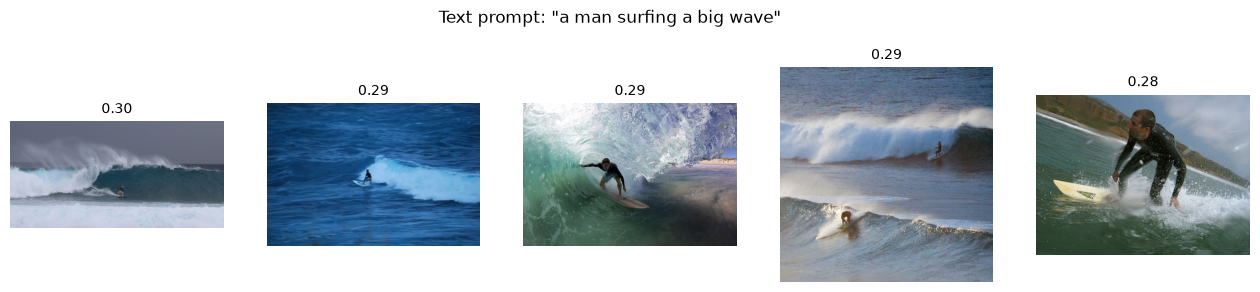

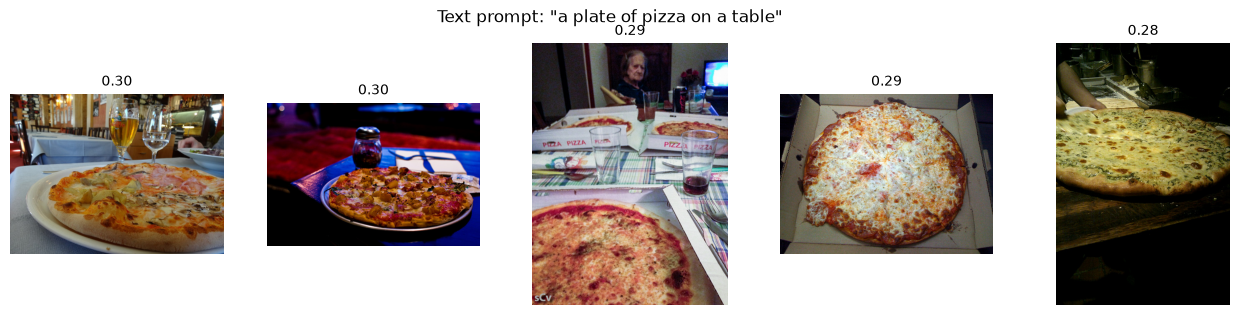

In [7]:
search_by_text("a giraffe in the wild")
search_by_text("a man surfing a big wave")
search_by_text("a plate of pizza on a table")

### 1b. Image → images

If the query image comes from the collection itself, it is its own best match (score 1.00), so the first result is the query again.
You can also pass your own picture, e.g. `search_by_image(Image.open("my_photo.jpg"))`.

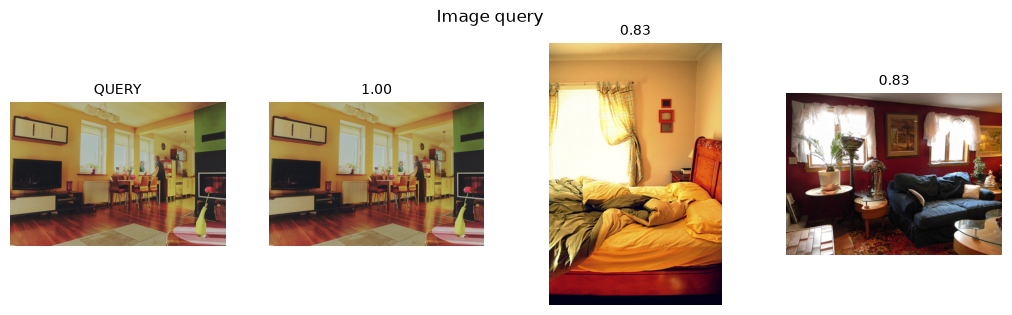

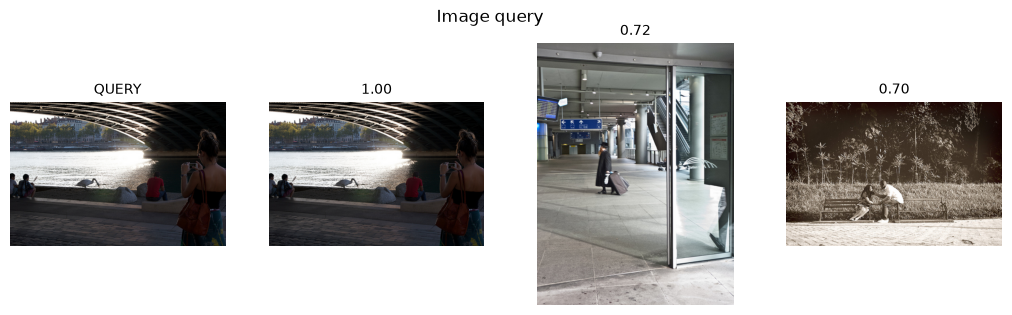

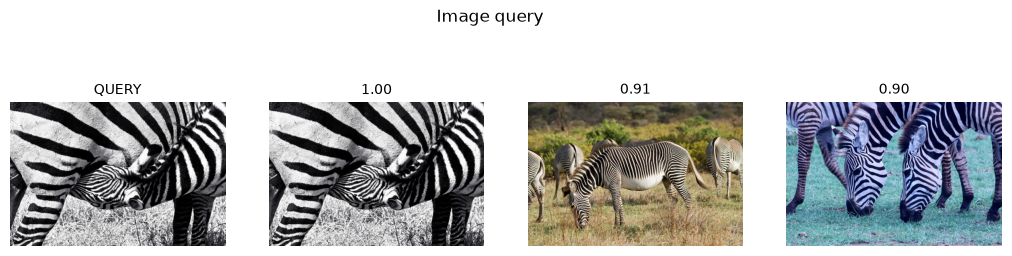

In [8]:
search_by_image(images[0])
search_by_image(images[10])
search_by_image(images[20])

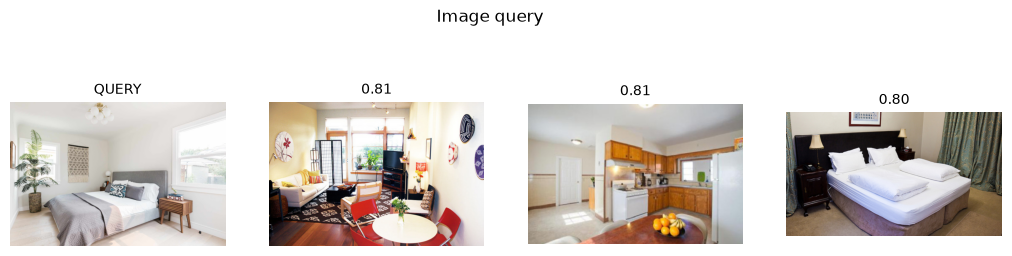

In [9]:
search_by_image(Image.open("image.png"))

---
# Part 2: LLaVA 1.5

First choose the picture and the question. **Both Part 2 and Part 3 will use them**, so the comparison is fair.

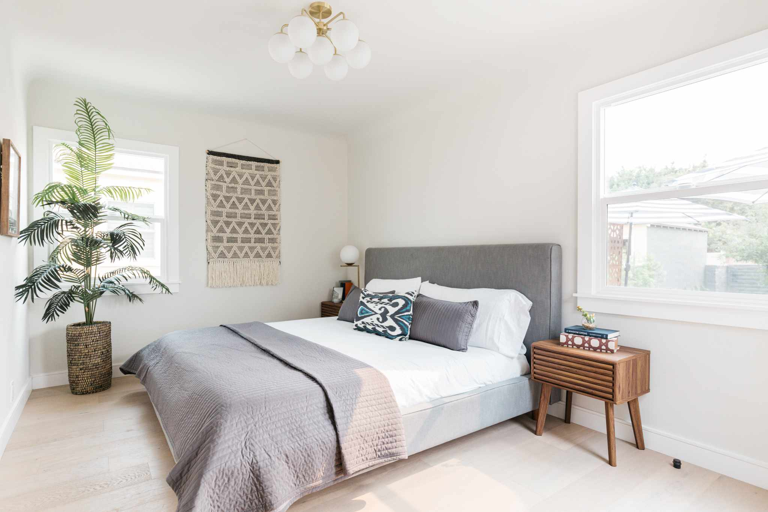

In [10]:
QUESTION = "What is happening in this picture? Describe it in detail."

try:                                   # Colab: upload a file from your computer
    from google.colab import files
    IMAGE_PATH = list(files.upload().keys())[0]
except ImportError:                    # Laptop: put the path of your image here
    IMAGE_PATH = "image.png"

image = Image.open(IMAGE_PATH).convert("RGB")
image.thumbnail((768, 768))            # keep the image small to save GPU memory
image

In [11]:
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

llava_id = "C:\\Users\\matin\\Desktop\\models\\llava_1.5"   # Colab: "llava-hf/llava-1.5-7b-hf"

bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                bnb_4bit_compute_dtype=dtype)

# device_map={"": 0} = put everything on the GPU (a clear error instead of silently offloading to CPU/disk)
llava = LlavaForConditionalGeneration.from_pretrained(
    llava_id, quantization_config=bnb_config, dtype=dtype, device_map={"": 0})
llava_processor = AutoProcessor.from_pretrained(llava_id)

W1127 20:20:12.560000 6348 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels
Loading weights: 100%|██████████| 686/686 [00:34<00:00, 19.91it/s] 


In [12]:
def ask_llava(image, question, max_new_tokens=300):
    # 1) build the chat prompt (it contains an <image> placeholder)
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = llava_processor.apply_chat_template(conversation, add_generation_prompt=True)

    # 2) turn image + prompt into tensors
    inputs = llava_processor(images=image, text=prompt, return_tensors="pt").to(llava.device, dtype)

    # 3) generate and keep only the newly generated tokens
    output = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return llava_processor.decode(new_tokens, skip_special_tokens=True)


llava_answer = ask_llava(image, QUESTION)
print("Question:", QUESTION)
print("\nLLaVA 1.5 says:\n", llava_answer)

Question: What is happening in this picture? Describe it in detail.

LLaVA 1.5 says:
 The image features a large bedroom with a neatly made bed. The bed is positioned in the center of the room, and it has a white comforter and pillows. The room is well-lit, with a window on the right side of the bed.

There are several decorative elements in the room, including a potted plant located on the left side of the bed, a vase placed on the right side of the bed, and a clock hanging on the wall. Additionally, there are two books placed on the right side of the bed, and a bottle can be seen on the left side of the room.


---
# Part 3: Qwen3-VL-8B-Instruct

Same image, same question, newer model. First we free the GPU memory used by LLaVA and CLIP.

In [ ]:
# Free GPU memory before loading the next model
llava = None
llava_processor = None
clip = None            
gc.collect()
torch.cuda.empty_cache()

free, total = torch.cuda.mem_get_info()
print(f"Free GPU memory: {free / 1e9:.1f} GB of {total / 1e9:.1f} GB")
print("Qwen3-VL-8B in 4-bit needs roughly 6-7 GB free.")

Free GPU memory: 7.3 GB of 8.6 GB
Qwen3-VL-8B in 4-bit needs roughly 6-7 GB free.


In [ ]:
from transformers import Qwen3VLForConditionalGeneration

qwen_id = "C:\\Users\\matin\\Desktop\\models\\Qwen3_VL_8B"   # Colab: "Qwen/Qwen3-VL-8B-Instruct"

qwen_bnb_config = BitsAndBytesConfig(
    load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=dtype,
    bnb_4bit_use_double_quant=True,
)

# device_map={"": 0} = everything on the GPU (no silent offload to CPU/disk)
qwen = Qwen3VLForConditionalGeneration.from_pretrained(
    qwen_id, quantization_config=qwen_bnb_config, dtype=dtype, device_map={"": 0})
qwen_processor = AutoProcessor.from_pretrained(qwen_id)

Loading weights: 100%|██████████| 750/750 [00:33<00:00, 22.67it/s] 


In [15]:
def ask_qwen(image, question, max_new_tokens=300):
    messages = [{"role": "user", "content": [{"type": "image", "image": image},
                                             {"type": "text", "text": question}]}]

    # The processor builds the prompt AND converts the image to tensors in one call
    inputs = qwen_processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt").to(qwen.device)

    output = qwen.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return qwen_processor.decode(new_tokens, skip_special_tokens=True)


qwen_answer = ask_qwen(image, QUESTION)
print("Question:", QUESTION)
print("\nQwen3-VL says:\n", qwen_answer)

c:\Users\matin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Question: What is happening in this picture? Describe it in detail.

Qwen3-VL says:
 This picture captures a serene, modern, and thoughtfully decorated bedroom, likely in a contemporary home. The room is bathed in soft, natural light, creating a calm and inviting atmosphere.

Here is a detailed description of the scene:

**Overall Impression:**
The room exudes a minimalist, coastal, or bohemian-chic aesthetic. It is clean, uncluttered, and features a harmonious color palette of neutrals — whites, grays, and natural wood tones — accented with pops of pattern and greenery.

**Key Elements:**

*   **The Bed:** The central focus is a large bed with a substantial, upholstered gray headboard. It is dressed in crisp white linens, topped with several pillows: two large white ones, a smaller gray one, and a standout decorative pillow with a bold, intricate black-and-white geometric pattern. A textured, quilted gray throw blanket is draped over the foot of the bed, adding warmth and layering.

*

In [16]:
print("=== LLaVA 1.5 ===\n" + llava_answer)
print("\n=== Qwen3-VL-8B ===\n" + qwen_answer)

=== LLaVA 1.5 ===
The image features a large bedroom with a neatly made bed. The bed is positioned in the center of the room, and it has a white comforter and pillows. The room is well-lit, with a window on the right side of the bed.

There are several decorative elements in the room, including a potted plant located on the left side of the bed, a vase placed on the right side of the bed, and a clock hanging on the wall. Additionally, there are two books placed on the right side of the bed, and a bottle can be seen on the left side of the room.

=== Qwen3-VL-8B ===
This picture captures a serene, modern, and thoughtfully decorated bedroom, likely in a contemporary home. The room is bathed in soft, natural light, creating a calm and inviting atmosphere.

Here is a detailed description of the scene:

**Overall Impression:**
The room exudes a minimalist, coastal, or bohemian-chic aesthetic. It is clean, uncluttered, and features a harmonious color palette of neutrals — whites, grays, and 

### Things to try
- Ask something specific: *"How many people are in the image?"*, *"What does the sign say?"* (OCR), *"What is unusual here?"*
- Use a picture with text, a chart or a screenshot. Which model reads it better?
- Change the question and call `ask_qwen(image, "your question")` again (the model stays loaded).
- Compare the three models: CLIP only *matches* images and text, LLaVA and Qwen3-VL can *generate* text about an image.